# rasher-qc walkthrough

This notebook walks through the inspection pipeline on one dataset: data → detector → tray decision → validation numbers. It only *reads* the results produced by the scripts (`run_all.sh`), so it runs in seconds. It uses the leakage-aware block split of the real data if present (run `run_pipeline.py` first), otherwise the synthetic set.

In [1]:
from pathlib import Path
import json, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from rasherqc import config
from rasherqc.dataset import load_dataset, tray_fail_label

DATA = config.DATA_DIR / 'pork-rasher-block'   # leakage-aware split; use 'synthetic' if the real data is not present
if not (DATA / 'data.yaml').is_file():
    DATA = config.DATA_DIR / 'synthetic'
TAG = DATA.name
TABLES = config.RESULTS_DIR / TAG / 'tables'
ds = load_dataset(DATA)
print('classes:', ds.names)
print({s: len(ds.split(s)) for s in ('train', 'valid', 'test')})

classes: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']
{'train': 872, 'valid': 155, 'test': 173}


## 1. Inputs: a tray image and its annotations

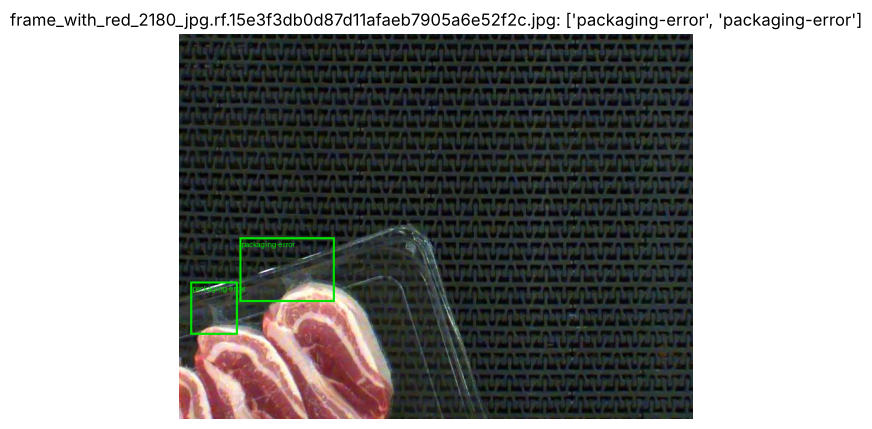

In [2]:
from PIL import ImageDraw
rec = next(r for r in ds.split('test') if len(r.classes) >= 2)
im = Image.open(rec.path).convert('RGB'); d = ImageDraw.Draw(im)
for b, c in zip(rec.boxes, rec.classes):
    d.rectangle(list(b), outline=(0, 230, 0), width=3); d.text((b[0]+3, b[1]+3), ds.names[c], fill=(0, 230, 0))
plt.figure(figsize=(7, 5)); plt.imshow(im); plt.axis('off'); plt.title(f'{rec.path.name}: {[ds.names[c] for c in rec.classes]}');

## 2. Input validation: unsupported images are rejected, not guessed

In [3]:
from rasherqc.io import validate_image
img = np.asarray(Image.open(rec.path).convert('RGB'))
for name, x in [('original', img), ('greyscale', img.mean(2).astype(np.uint8)),
                ('very dark', (img * 0.05).astype(np.uint8)), ('thumbnail', img[::4, ::4])]:
    _, r = validate_image(x)
    print(f'{name:10s} ok={r.ok}  {r.reasons}')

original   ok=True  []
greyscale  ok=False  ['greyscale image; RGB colour is required']
very dark  ok=False  ['exposure out of range (mean grey 2.0, allowed 20.0-235.0)']
thumbnail  ok=False  ['image too small (180x135); minimum side 240px']


## 3. Detector output and the tray decision

{
 "status": "FAIL",
 "score": 0.2035,
 "defects": [
  {
   "class": "unsealed",
   "confidence": 0.2035,
   "box_xyxy": [
    3.1,
    323.5,
    310.0,
    539.0
   ],
   "area_frac": 0.17014
  },
  {
   "class": "packaging-error",
   "confidence": 0.1042,
   "box_xyxy": [
    114.8,
    297.3,
    220.8,
    403.7
   ],
   "area_frac": 0.02901
  },
  {
   "class": "packaging-error",
   "confidence": 0.0768,
   "box_xyxy": [
    18.6,
    301.3,
    246.6,
    426.2
   ],
   "area_frac": 0.07327
  }
 ],
 "reasons": []
}


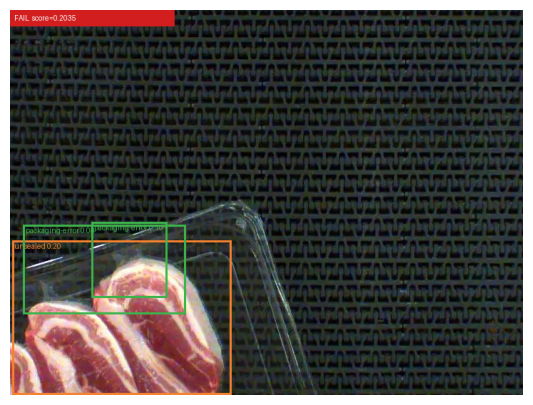

In [4]:
from rasherqc.detector import Detector
from rasherqc.decision import decide
from rasherqc.report import annotate
ev = json.loads((TABLES / 'evaluation.json').read_text())
w = config.MODEL_DIR / TAG / 'yolo_pretrained.pt'
if w.is_file():
    det = Detector(w)
    t = ev['methods']['yolo_pretrained']['tray']
    res = decide(det.predict([img])[0], det.names, ds.defect_ids, (img.shape[1], img.shape[0]), t['fail_conf'], t['review_low'])
    print(json.dumps(res.to_dict(), indent=1))
    plt.figure(figsize=(7, 5)); plt.imshow(annotate(img, res, det.names)); plt.axis('off');
else:
    print('train the detector first: python scripts/02_train_detectors.py')

## 4. Validation summary
All numbers below come from `results/<tag>/tables/*.json`; the report quotes `results/<tag>/SUMMARY.md`, generated from the same files.

In [5]:
for n, m in ev['methods'].items():
    t = m['tray']; c = t['test_at_fail_conf']
    line = f"{n:16s} tray AUC={t['test_auc']:.3f}  fail_conf={t['fail_conf']:.3f}  recall={c['fail_recall']:.3f}  false-reject={c['false_reject_rate']:.3f}"
    if 'test' in m: line += f"  mAP50={m['test']['map50']:.3f}  mAP50-95={m['test']['map50_95']:.3f}"
    print(line)

yolo_pretrained  tray AUC=0.862  fail_conf=0.079  recall=0.978  false-reject=0.564  mAP50=0.547  mAP50-95=0.301
yolo_scratch     tray AUC=0.855  fail_conf=0.016  recall=0.985  false-reject=0.795  mAP50=0.270  mAP50-95=0.128
rf_baseline      tray AUC=0.673  fail_conf=0.419  recall=0.978  false-reject=0.923


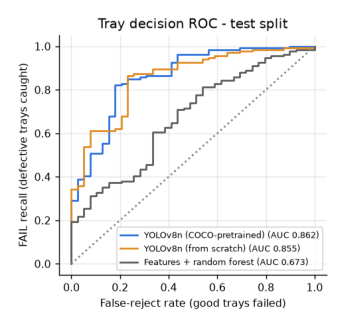

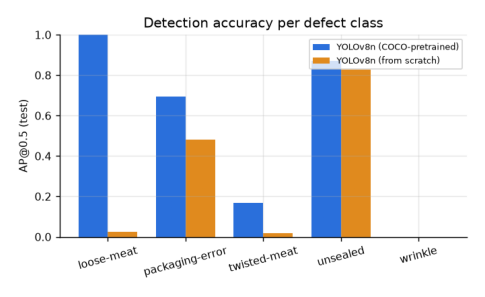

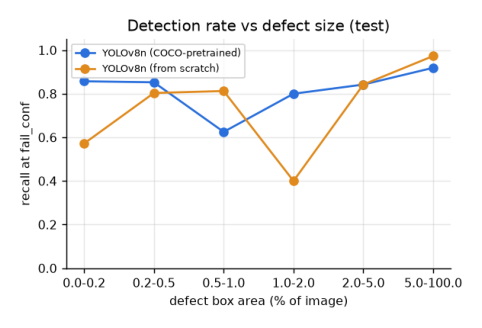

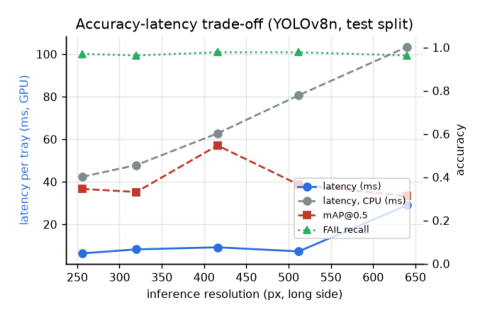

In [6]:
fig_dir = config.RESULTS_DIR / TAG / 'figures'
for f in ['tray_roc.png', 'ap_per_class.png', 'recall_vs_size.png', 'latency_vs_imgsz.png']:
    p = fig_dir / f
    if p.is_file():
        plt.figure(figsize=(6, 4)); plt.imshow(Image.open(p)); plt.axis('off')

## 5. Verification example: AP by hand vs the library
A three-prediction case whose AP can be worked out on paper (see `tests/test_metrics.py`).

In [7]:
from rasherqc.metrics import pr_curve, average_precision
rec_, pre_ = pr_curve(np.array([0.9, 0.8, 0.7]), np.array([True, False, True]), n_gt=2)
print('recall', rec_, 'precision', pre_.round(3))
print('AP continuous =', average_precision(rec_, pre_, 'continuous'), ' (hand: 0.5*1 + 0.5*2/3 = 0.8333)')

recall [        0.5         0.5           1] precision [          1         0.5       0.667]
AP continuous = 0.8333333333333333  (hand: 0.5*1 + 0.5*2/3 = 0.8333)
